In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load raw data 
df_raw = pd.read_csv('credit.csv')

# Working copy 
df = df_raw.copy()

In [4]:
# Numeric columns
numeric_cols_raw = df_raw.select_dtypes(include='number').drop(columns=['ID']).columns.tolist()

# Categorical columns
categorical_cols = ['Telephone', 'Foreign_Worker', 'Approval']

In [5]:
def plot_all_histograms(dataframe, cols, title_suffix, filename, color='steelblue'):
    n = len(cols)
    ncols = 4
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows * 4))
    axes = axes.flatten()
    for i, col in enumerate(cols):
        axes[i].hist(dataframe[col].dropna(), bins=20, color=color, edgecolor='black')
        axes[i].set_title(col)
        axes[i].set_xlabel('Value')
        axes[i].set_ylabel('Frequency')
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle(f'Histograms - {title_suffix}', fontsize=14, y=1.01)
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()

def plot_all_boxplots(dataframe, cols, title_suffix, filename, color='steelblue'):
    n = len(cols)
    ncols = 4
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows * 4))
    axes = axes.flatten()
    for i, col in enumerate(cols):
        axes[i].boxplot(dataframe[col].dropna(), vert=False, patch_artist=True,
                        boxprops=dict(facecolor=color, color='black'))
        axes[i].set_title(col)
        axes[i].set_xlabel('Value')
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle(f'Boxplots - {title_suffix}', fontsize=14, y=1.01)
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()

def plot_all_countplots(dataframe, cols, title_suffix, filename):
    n = len(cols)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 4))
    if n == 1:
        axes = [axes]
    for i, col in enumerate(cols):
        dataframe[col].value_counts().plot(kind='bar', ax=axes[i], color='lightcoral', edgecolor='black')
        axes[i].set_title(col)
        axes[i].set_xlabel('Value')
        axes[i].set_ylabel('Count')
        axes[i].tick_params(axis='x', rotation=0)
    plt.suptitle(f'Countplots - {title_suffix}', fontsize=14)
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()

def plot_correlation_heatmap(dataframe, cols, title_suffix, filename):
    corr = dataframe[cols].corr()
    plt.figure(figsize=(16, 12))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
    plt.title(f'Correlation Heatmap - {title_suffix}', fontsize=14)
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()

In [6]:
# Data overview
print('Shape:', df_raw.shape)
print()
print('Data Types:')
print(df_raw.dtypes)

Shape: (1000, 23)

Data Types:
ID                    int64
Checking_Account      int64
Duration              int64
Payment_Status        int64
Purpose               int64
Amount                int64
Savings_Account       int64
Employment            int64
Installment           int64
Personal_Status       int64
Guarantors            int64
Residence_Length      int64
Assets                int64
Age                 float64
Credit_Rating         int64
Existing_Credits    float64
Housing_Type          int64
Num_Credits           int64
Occupation            int64
Dependents            int64
Telephone            object
Foreign_Worker       object
Approval              int64
dtype: object


In [7]:
# Summary statistics numeric
print('Summary Statistics (Numeric)')
print(df_raw.describe())

Summary Statistics (Numeric)
                ID  Checking_Account     Duration  Payment_Status  \
count  1000.000000       1000.000000  1000.000000      1000.00000   
mean    500.500000          2.577000    20.828000         2.54500   
std     288.819436          1.257638    11.959827         1.08312   
min       1.000000          1.000000     4.000000         0.00000   
25%     250.750000          1.000000    12.000000         2.00000   
50%     500.500000          2.000000    18.000000         2.00000   
75%     750.250000          4.000000    24.000000         4.00000   
max    1000.000000          4.000000    72.000000         4.00000   

           Purpose        Amount  Savings_Account   Employment  Installment  \
count  1000.000000   1000.000000      1000.000000  1000.000000  1000.000000   
mean      2.828000   3275.058000         2.105000     3.384000     2.973000   
std       2.744439   2803.297505         1.580023     1.208306     1.118715   
min       0.000000    250.000000 

In [8]:
# Summary statistics all columns
print('Summary Statistics (All Columns)')
print(df_raw.describe(include='all'))

Summary Statistics (All Columns)
                 ID  Checking_Account     Duration  Payment_Status  \
count   1000.000000       1000.000000  1000.000000      1000.00000   
unique          NaN               NaN          NaN             NaN   
top             NaN               NaN          NaN             NaN   
freq            NaN               NaN          NaN             NaN   
mean     500.500000          2.577000    20.828000         2.54500   
std      288.819436          1.257638    11.959827         1.08312   
min        1.000000          1.000000     4.000000         0.00000   
25%      250.750000          1.000000    12.000000         2.00000   
50%      500.500000          2.000000    18.000000         2.00000   
75%      750.250000          4.000000    24.000000         4.00000   
max     1000.000000          4.000000    72.000000         4.00000   

            Purpose        Amount  Savings_Account   Employment  Installment  \
count   1000.000000   1000.000000      1000.00

In [9]:
# Missing value
print('Missing Values (before cleaning)')
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
print(pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})[missing > 0])

Missing Values (before cleaning)
                  Missing Count  Missing %
Age                          56        5.6
Existing_Credits             58        5.8


In [10]:
# Unique values in messy columns
print('Telephone:     ', df_raw['Telephone'].unique().tolist())
print('Foreign_Worker:', df_raw['Foreign_Worker'].unique().tolist())

Telephone:      ['NO', 'no', 'n', 'No', 'Yes', 'N', 'yes', 'y', 'YES', 'Y']
Foreign_Worker: ['yes', 'Yes', 'Y', 'YES', 'y', 'N', 'No', 'NO', 'n', 'no']


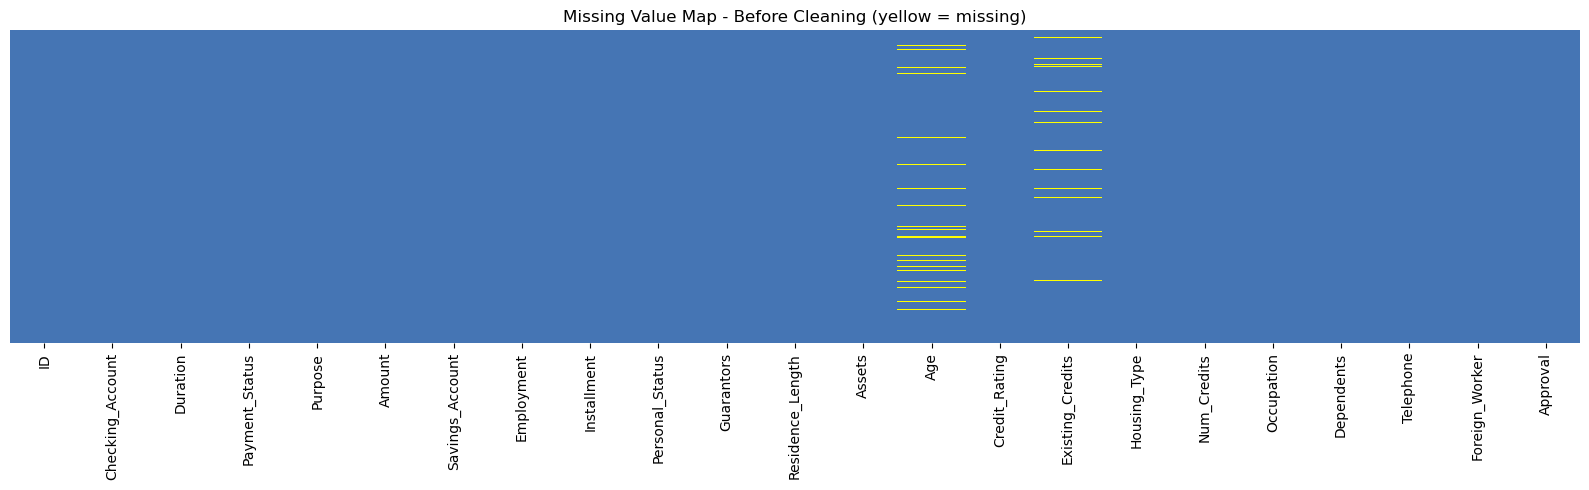

In [48]:
plt.figure(figsize=(16,5))
sns.heatmap(
    df_raw.isnull(),
    cbar=False,
    yticklabels=False,
    cmap=['#4575b4', 'yellow']  # white = no missing, red = missing
)

plt.title('Missing Value Map - Before Cleaning (yellow = missing)')
plt.tight_layout()
plt.savefig('before_missing_heatmap.png', dpi=150)
plt.show()

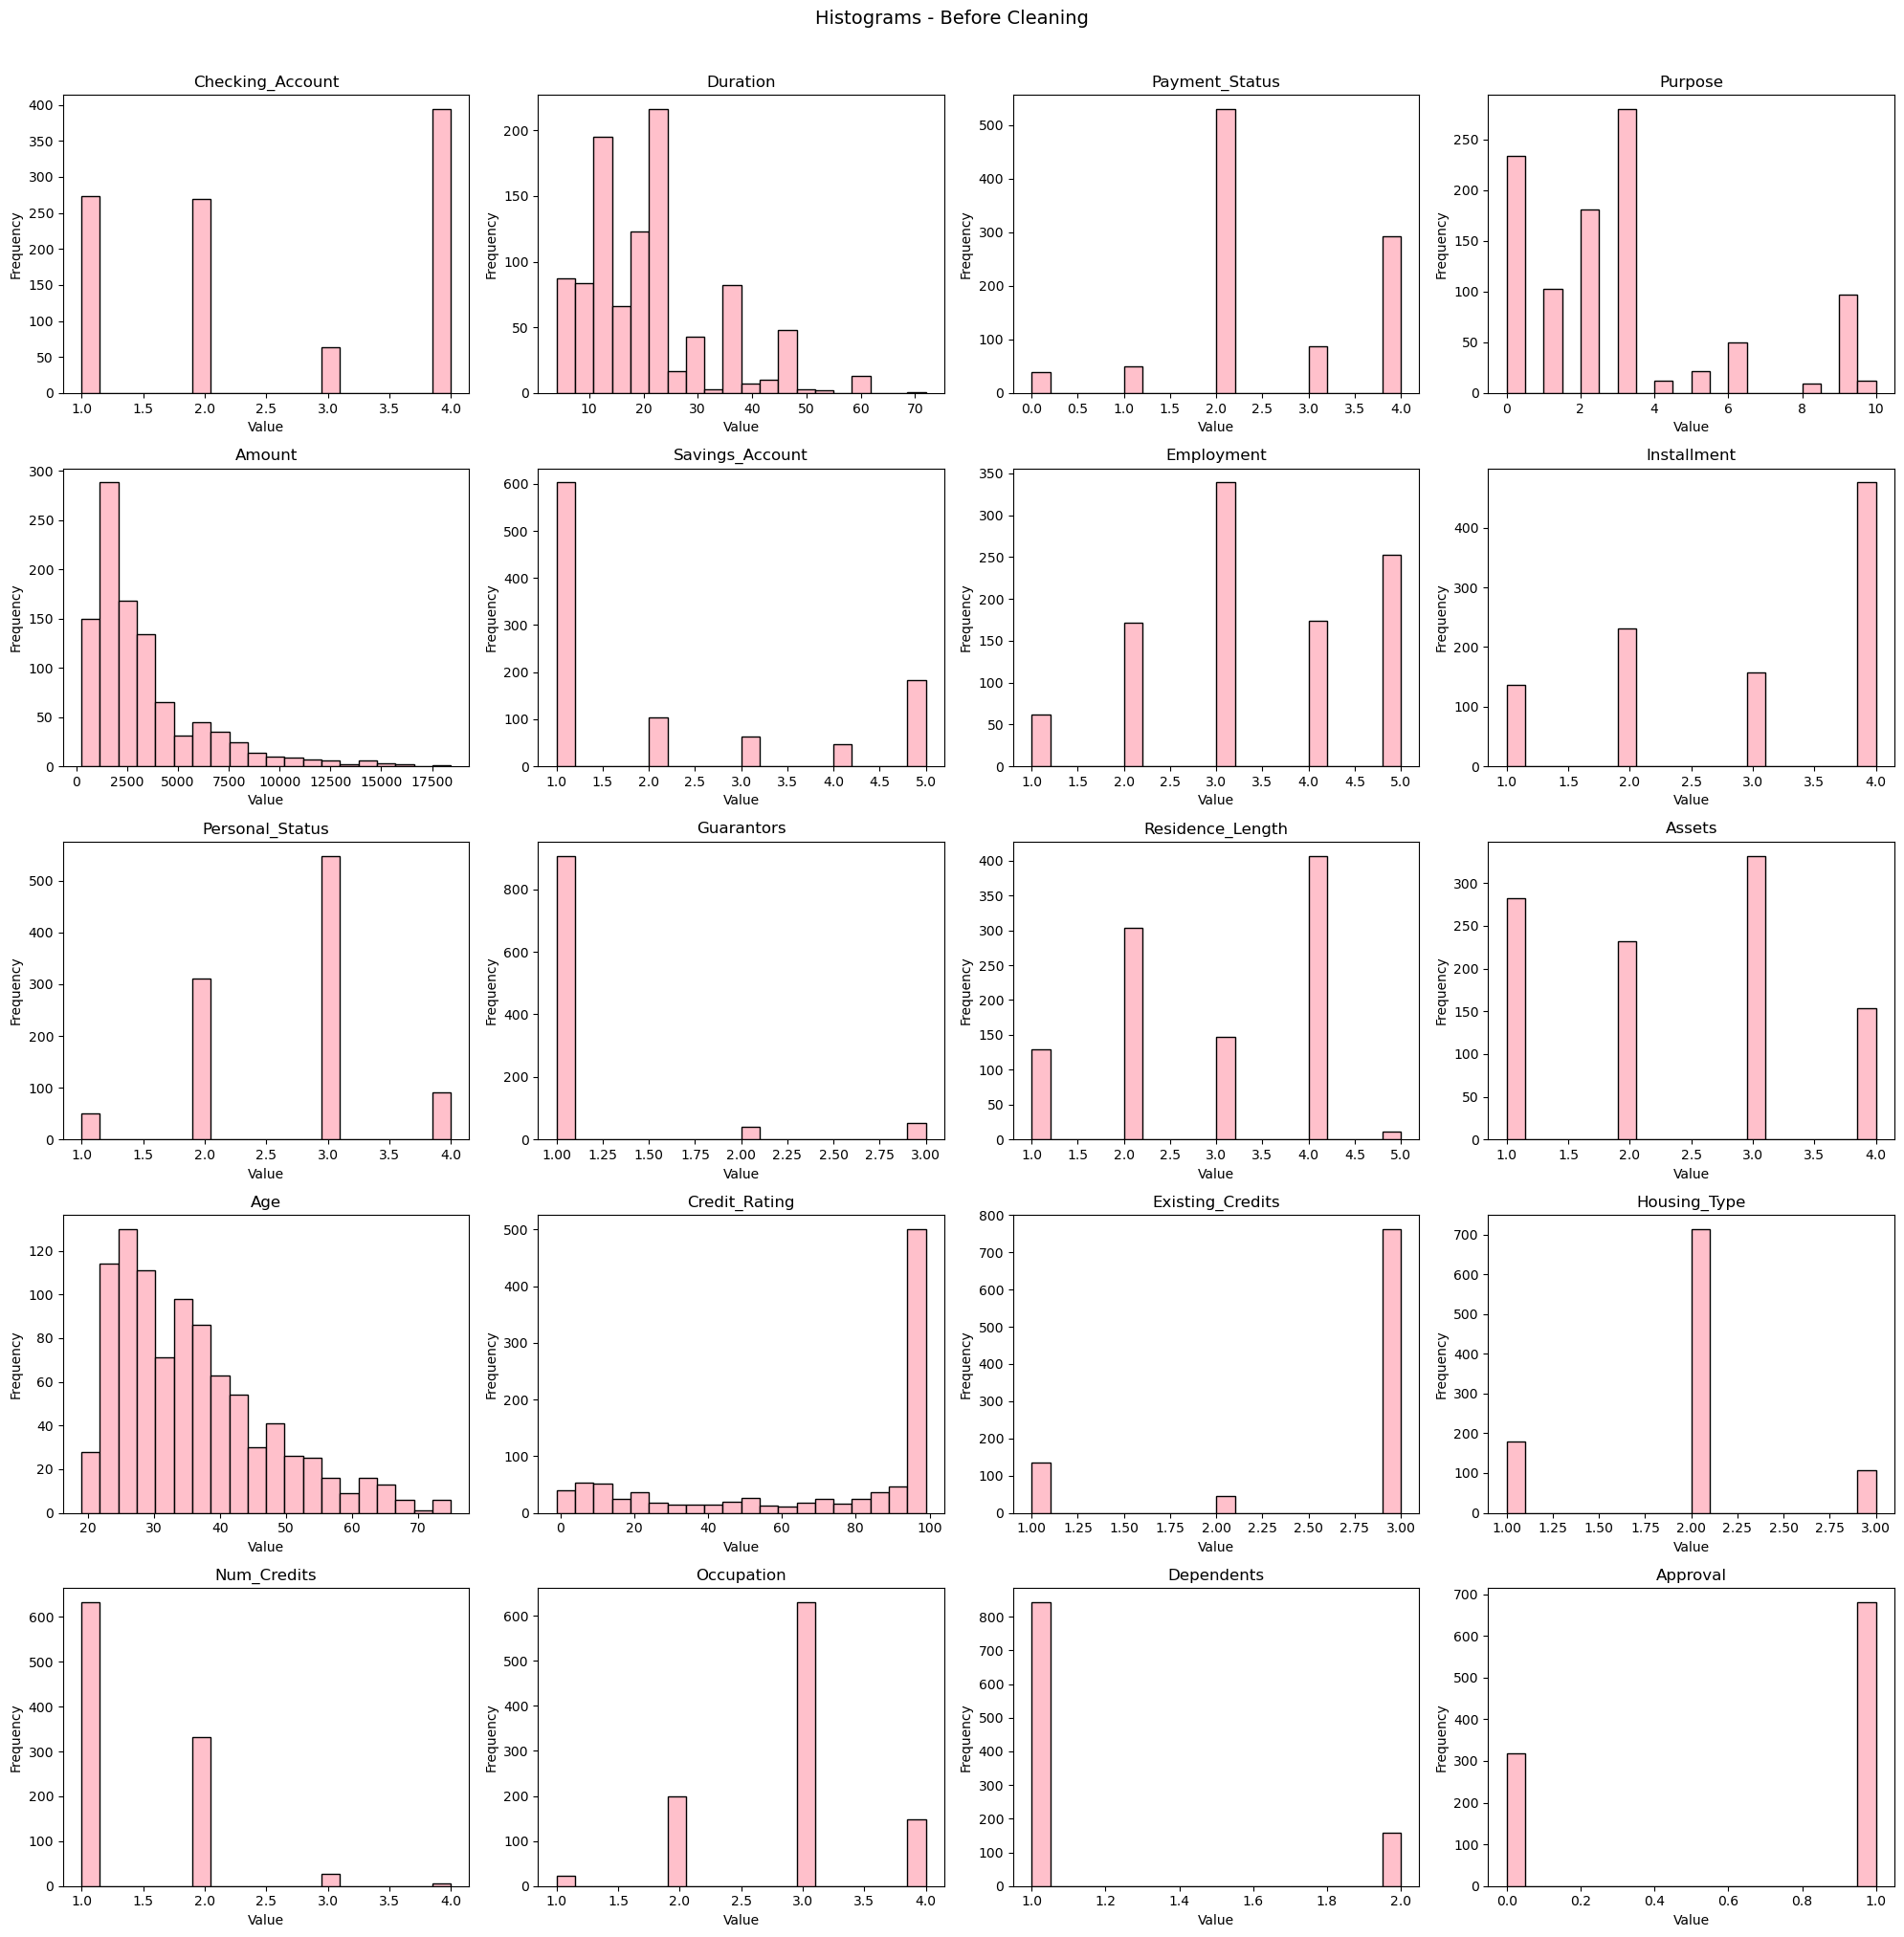

In [16]:
# Histograms
plot_all_histograms(df_raw, numeric_cols_raw, title_suffix='Before Cleaning', filename='before_histograms.png', color='pink')

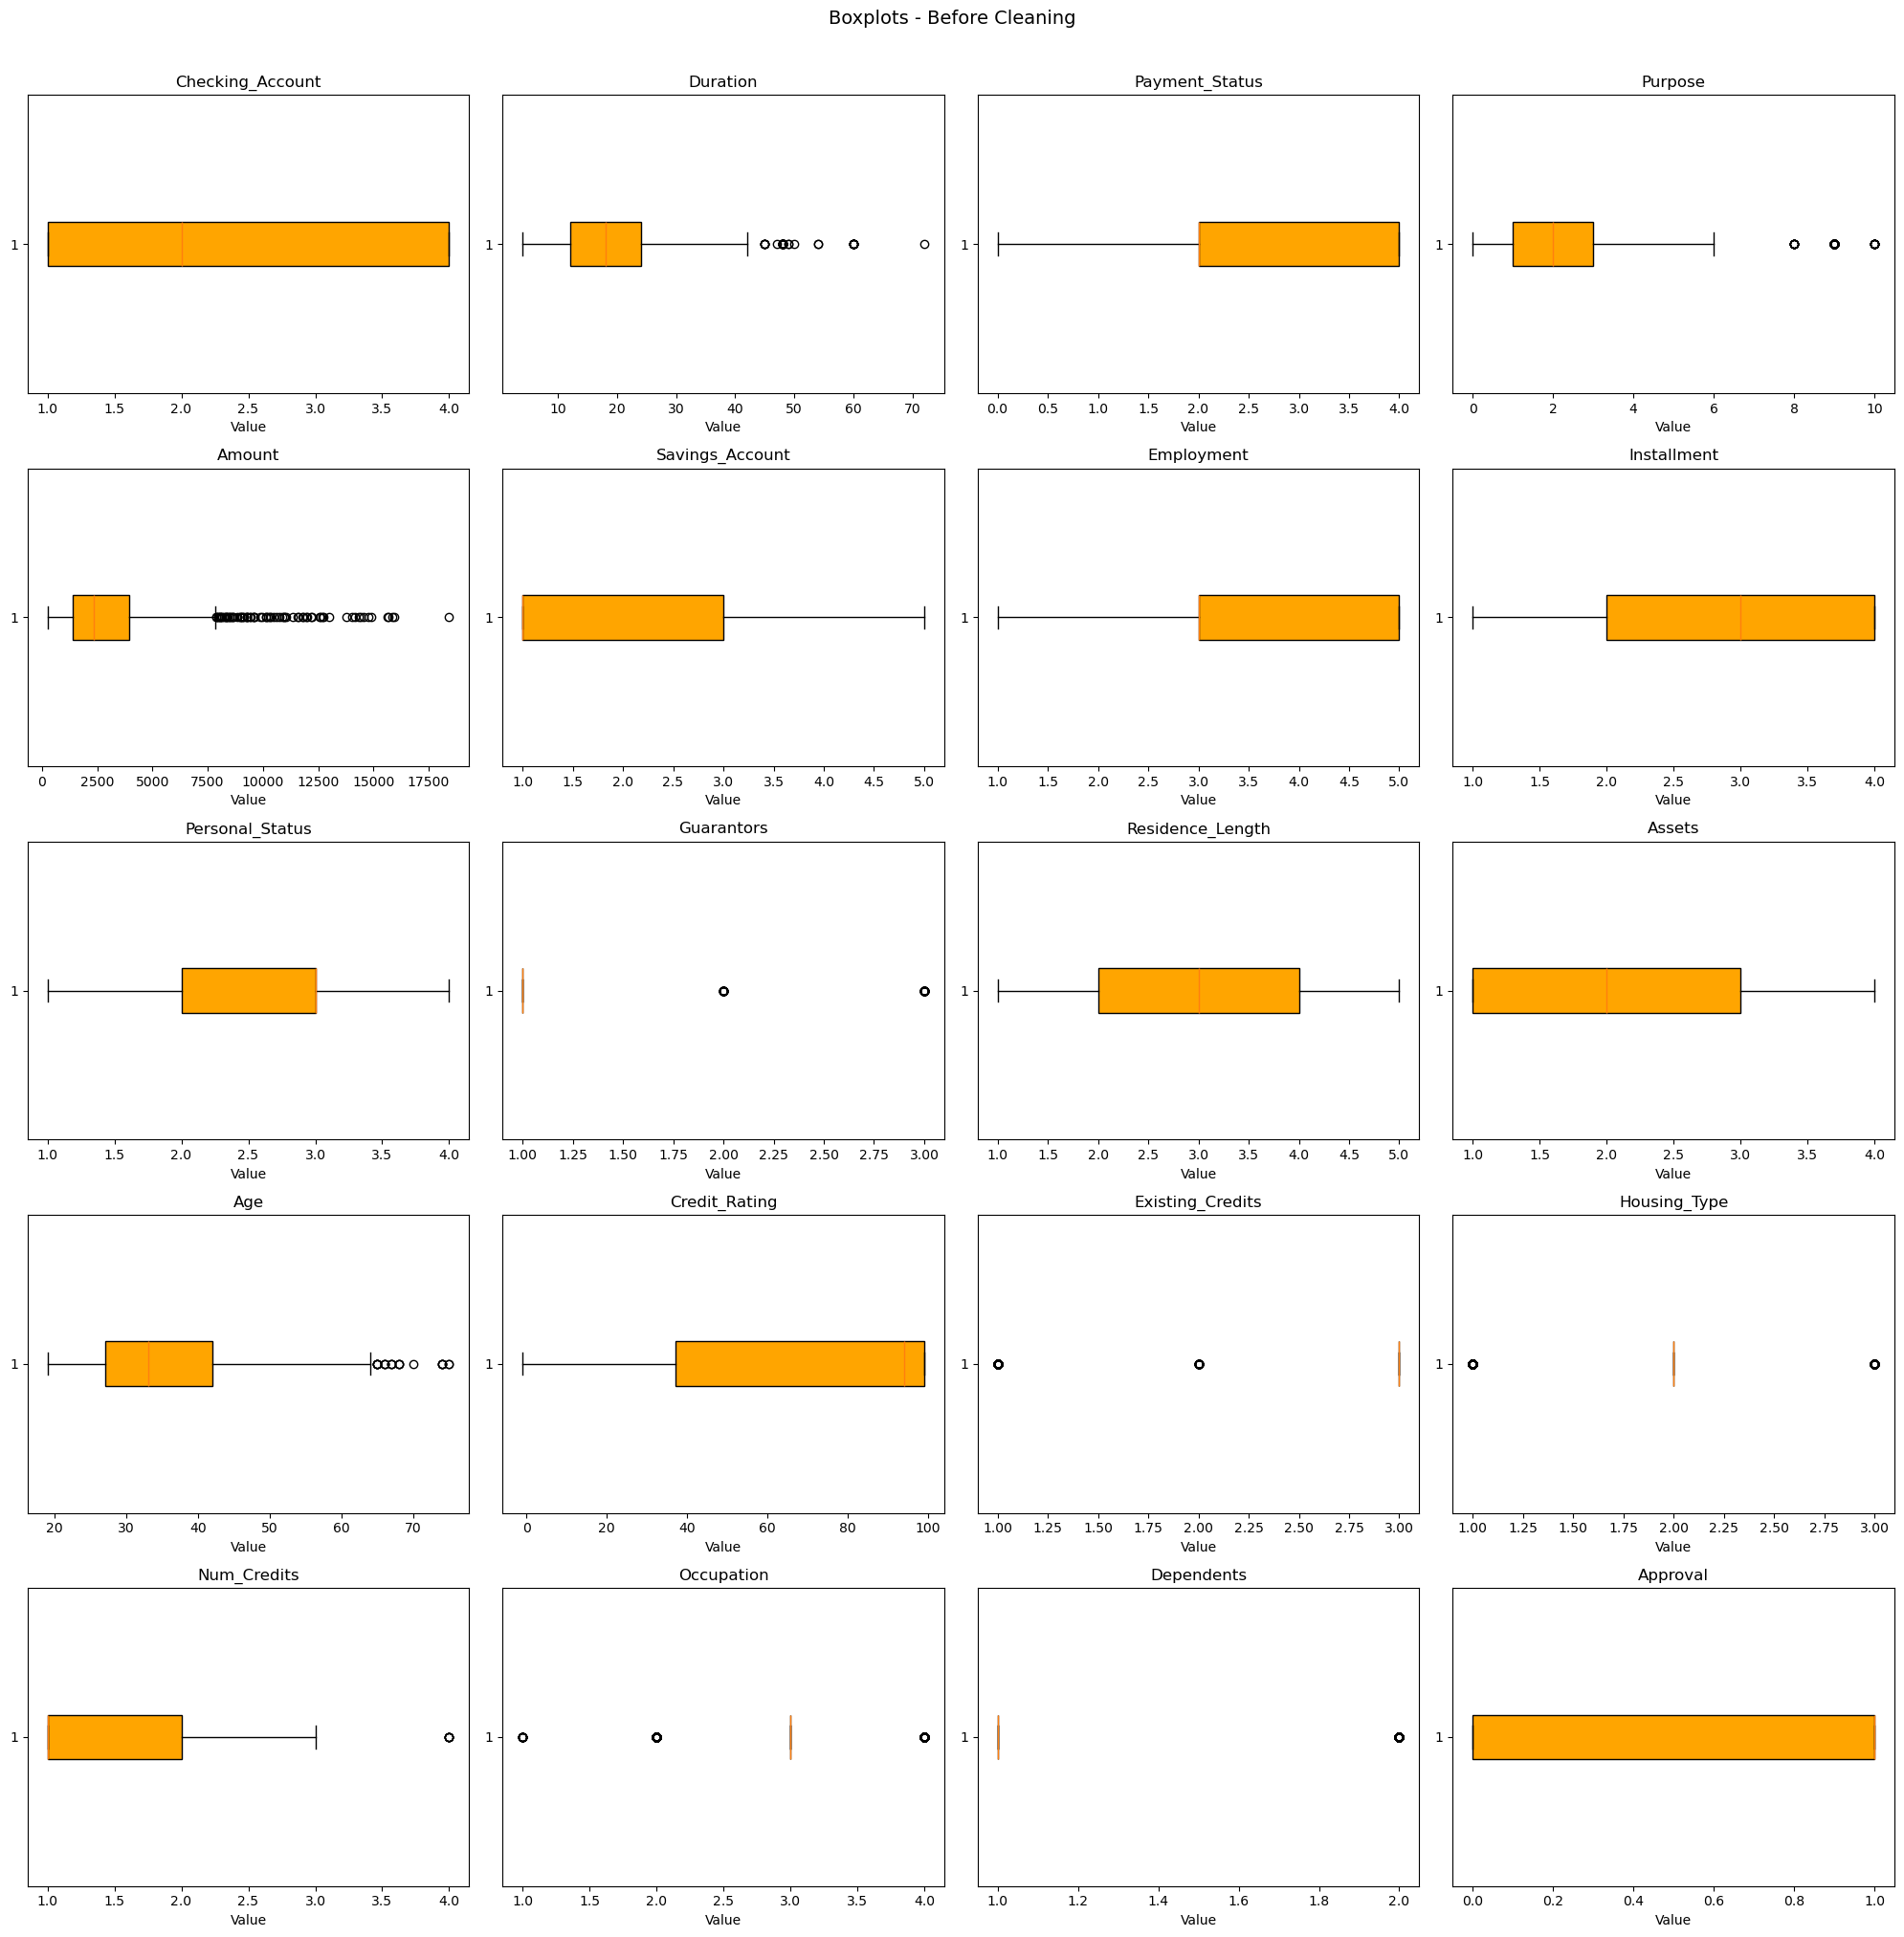

In [17]:
# Boxplots
plot_all_boxplots(df_raw, numeric_cols_raw, title_suffix='Before Cleaning', filename='before_boxplots.png', color='orange')

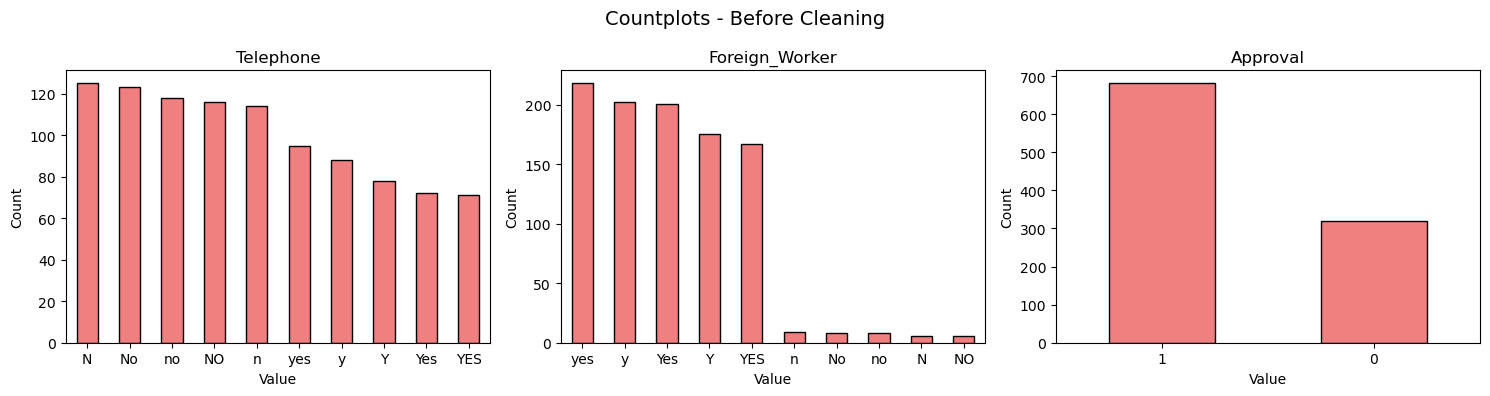

In [18]:
# Countplots
plot_all_countplots(df_raw, categorical_cols, title_suffix='Before Cleaning', filename='before_countplots.png')

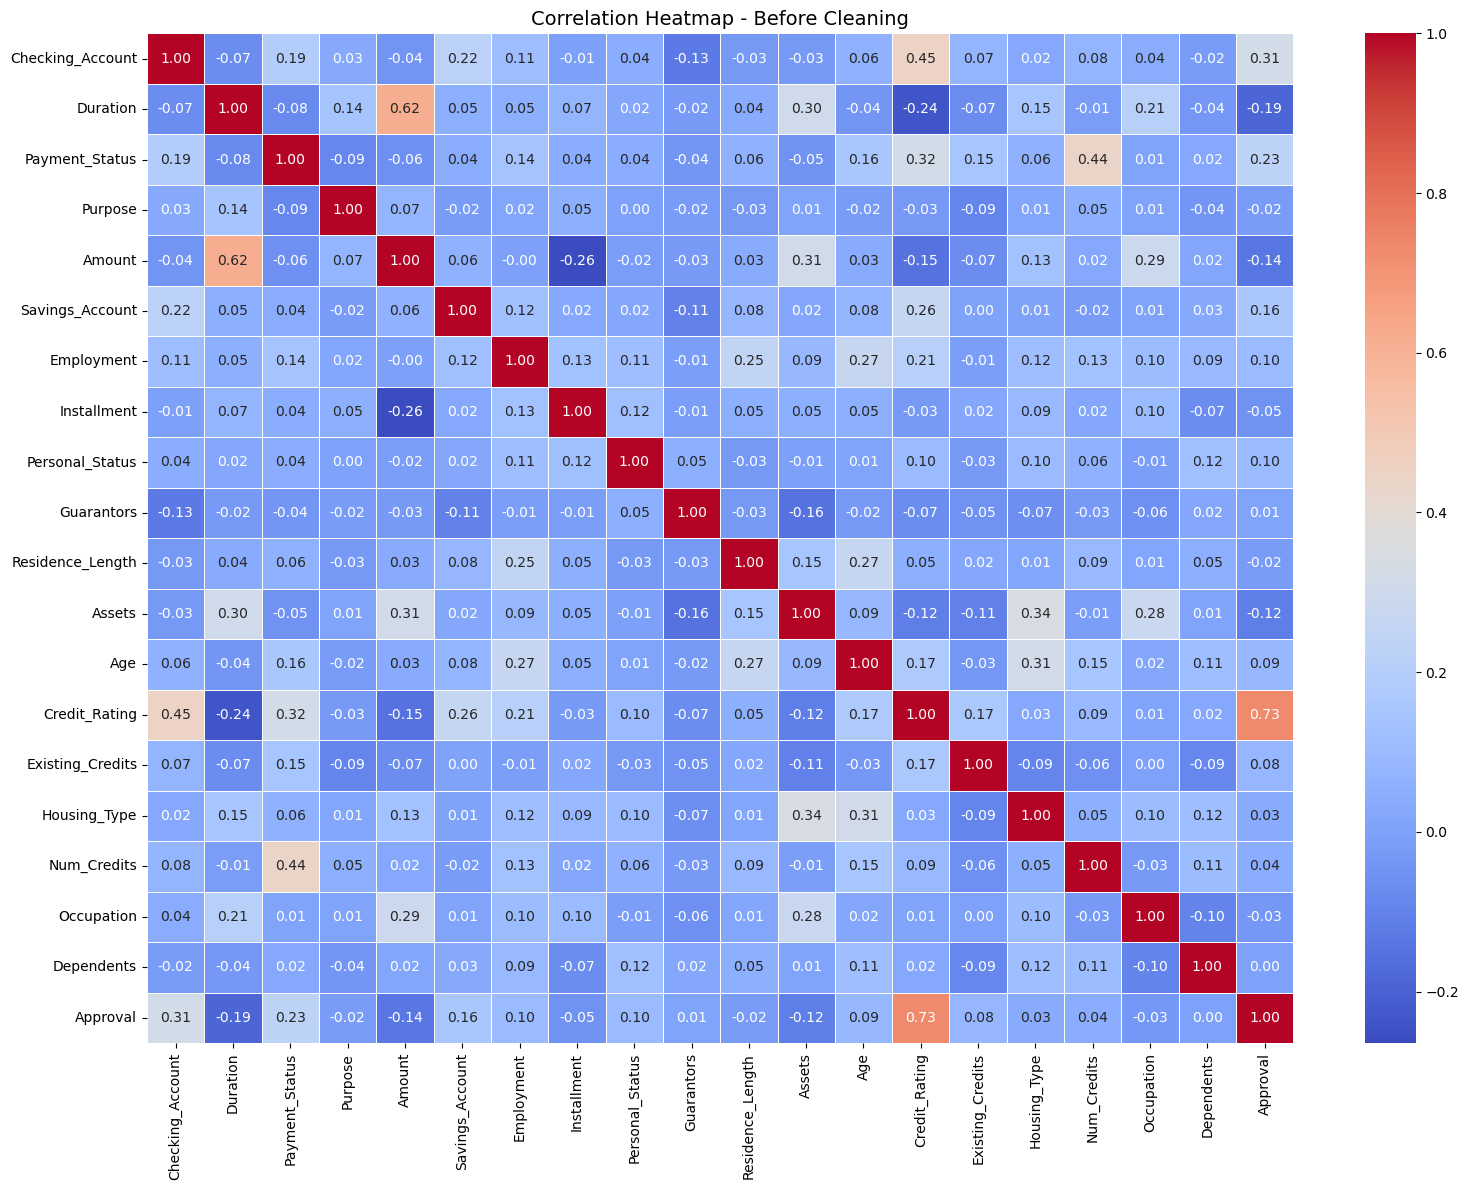

In [19]:
# Correlation heatmap
plot_correlation_heatmap(df_raw, numeric_cols_raw, title_suffix='Before Cleaning', filename='before_correlation_heatmap.png')

In [20]:
# Standardise Data Columns
df['Telephone']      = df['Telephone'].apply(lambda x: str(x).strip().lower())
df['Foreign_Worker'] = df['Foreign_Worker'].apply(lambda x: str(x).strip().lower())

yes_variants = {'yes': 1, 'y': 1, 'no': 0, 'n': 0}
df['Telephone']      = df['Telephone'].map(yes_variants)
df['Foreign_Worker'] = df['Foreign_Worker'].map(yes_variants)

print('Telephone unique values:     ', df['Telephone'].unique())
print('Foreign_Worker unique values:', df['Foreign_Worker'].unique())

Telephone unique values:      [0 1]
Foreign_Worker unique values: [1 0]


In [21]:
# Dropping Personal_Status as it combines gender and marital status
# inconsistently, where detailed marital categories exist only for males,
# leading to biased or ambiguous interpretation during analysis. 
df.drop(columns=['Personal_Status'], inplace=True) 
print(df.columns.tolist())

['ID', 'Checking_Account', 'Duration', 'Payment_Status', 'Purpose', 'Amount', 'Savings_Account', 'Employment', 'Installment', 'Guarantors', 'Residence_Length', 'Assets', 'Age', 'Credit_Rating', 'Existing_Credits', 'Housing_Type', 'Num_Credits', 'Occupation', 'Dependents', 'Telephone', 'Foreign_Worker', 'Approval']


In [22]:
# Remove duplicate rows
df.drop_duplicates(inplace=True)
print('Rows after dedup:', len(df))

Rows after dedup: 1000


In [23]:
# Impute Age with median 
age_median = df['Age'].median() #robust to right-skewed distribution
df['Age']  = df['Age'].fillna(age_median).astype(int)
print(f'Age imputed with median ({age_median})')

# Impute Existing_Credits with mode 
credits_mode           = df['Existing_Credits'].mode().iloc[0] #low-cardinality column (values 1-3)
df['Existing_Credits'] = df['Existing_Credits'].fillna(credits_mode).astype(int)
print(f'Existing_Credits imputed with mode ({credits_mode})')

Age imputed with median (33.0)
Existing_Credits imputed with mode (3.0)


In [24]:
# Confirming no missing values remain
print('Missing Values (after cleaning)')
print(f'Total: {df.isnull().sum().sum()}')
print(df.isnull().sum())

Missing Values (after cleaning)
Total: 0
ID                  0
Checking_Account    0
Duration            0
Payment_Status      0
Purpose             0
Amount              0
Savings_Account     0
Employment          0
Installment         0
Guarantors          0
Residence_Length    0
Assets              0
Age                 0
Credit_Rating       0
Existing_Credits    0
Housing_Type        0
Num_Credits         0
Occupation          0
Dependents          0
Telephone           0
Foreign_Worker      0
Approval            0
dtype: int64


In [25]:
# Saving cleaned dataset
df.to_csv('credit_cleaned.csv', index=False)
print('Saved: credit_cleaned.csv')

Saved: credit_cleaned.csv


In [26]:
# Updating column lists
numeric_cols_after     = df.select_dtypes(include='number').drop(columns=['ID']).columns.tolist()
categorical_cols_after = ['Approval']

In [27]:
# Data overview - Post Cleaning
print('Shape:', df.shape)
print()
print('Data Types:')
print(df.dtypes)

Shape: (1000, 22)

Data Types:
ID                  int64
Checking_Account    int64
Duration            int64
Payment_Status      int64
Purpose             int64
Amount              int64
Savings_Account     int64
Employment          int64
Installment         int64
Guarantors          int64
Residence_Length    int64
Assets              int64
Age                 int64
Credit_Rating       int64
Existing_Credits    int64
Housing_Type        int64
Num_Credits         int64
Occupation          int64
Dependents          int64
Telephone           int64
Foreign_Worker      int64
Approval            int64
dtype: object


In [28]:
# Summary statistics 
print('Summary Statistics (Numeric)')
print(df.describe())

Summary Statistics (Numeric)
                ID  Checking_Account     Duration  Payment_Status  \
count  1000.000000       1000.000000  1000.000000      1000.00000   
mean    500.500000          2.577000    20.828000         2.54500   
std     288.819436          1.257638    11.959827         1.08312   
min       1.000000          1.000000     4.000000         0.00000   
25%     250.750000          1.000000    12.000000         2.00000   
50%     500.500000          2.000000    18.000000         2.00000   
75%     750.250000          4.000000    24.000000         4.00000   
max    1000.000000          4.000000    72.000000         4.00000   

           Purpose        Amount  Savings_Account   Employment  Installment  \
count  1000.000000   1000.000000      1000.000000  1000.000000  1000.000000   
mean      2.828000   3275.058000         2.105000     3.384000     2.973000   
std       2.744439   2803.297505         1.580023     1.208306     1.118715   
min       0.000000    250.000000 

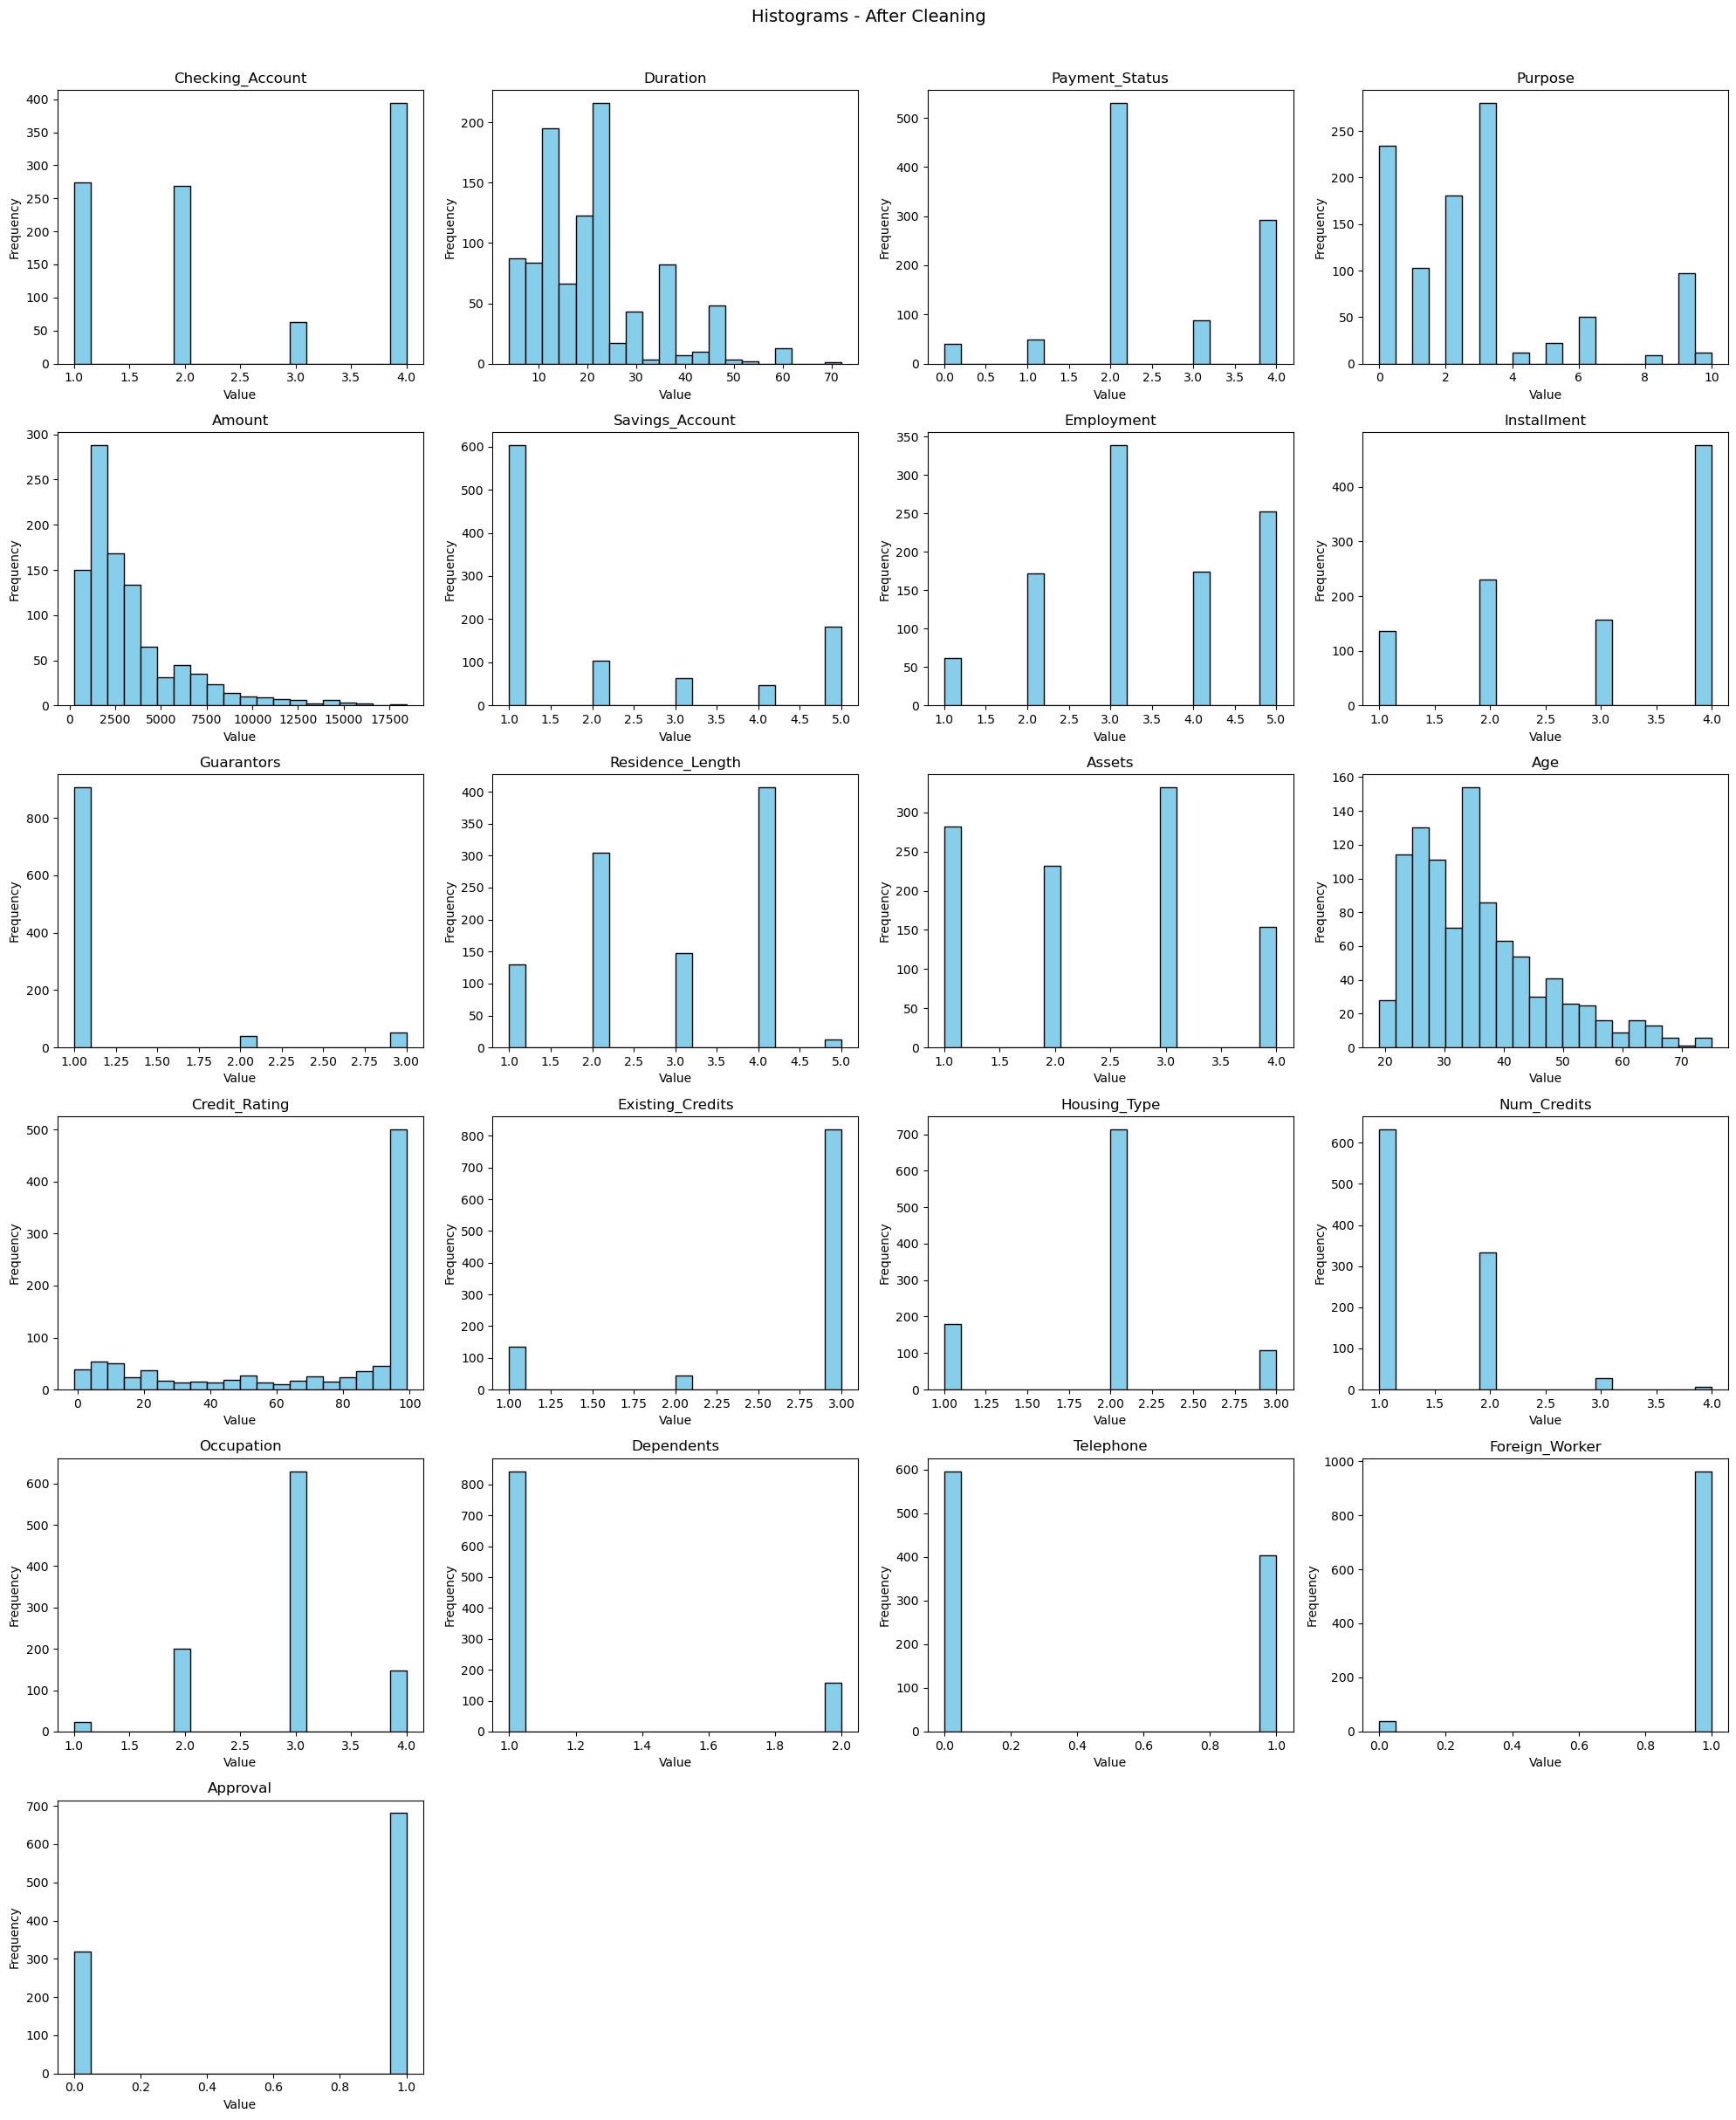

In [29]:
# Histograms 
plot_all_histograms(df, numeric_cols_after, title_suffix='After Cleaning', filename='after_histograms.png', color='skyblue')

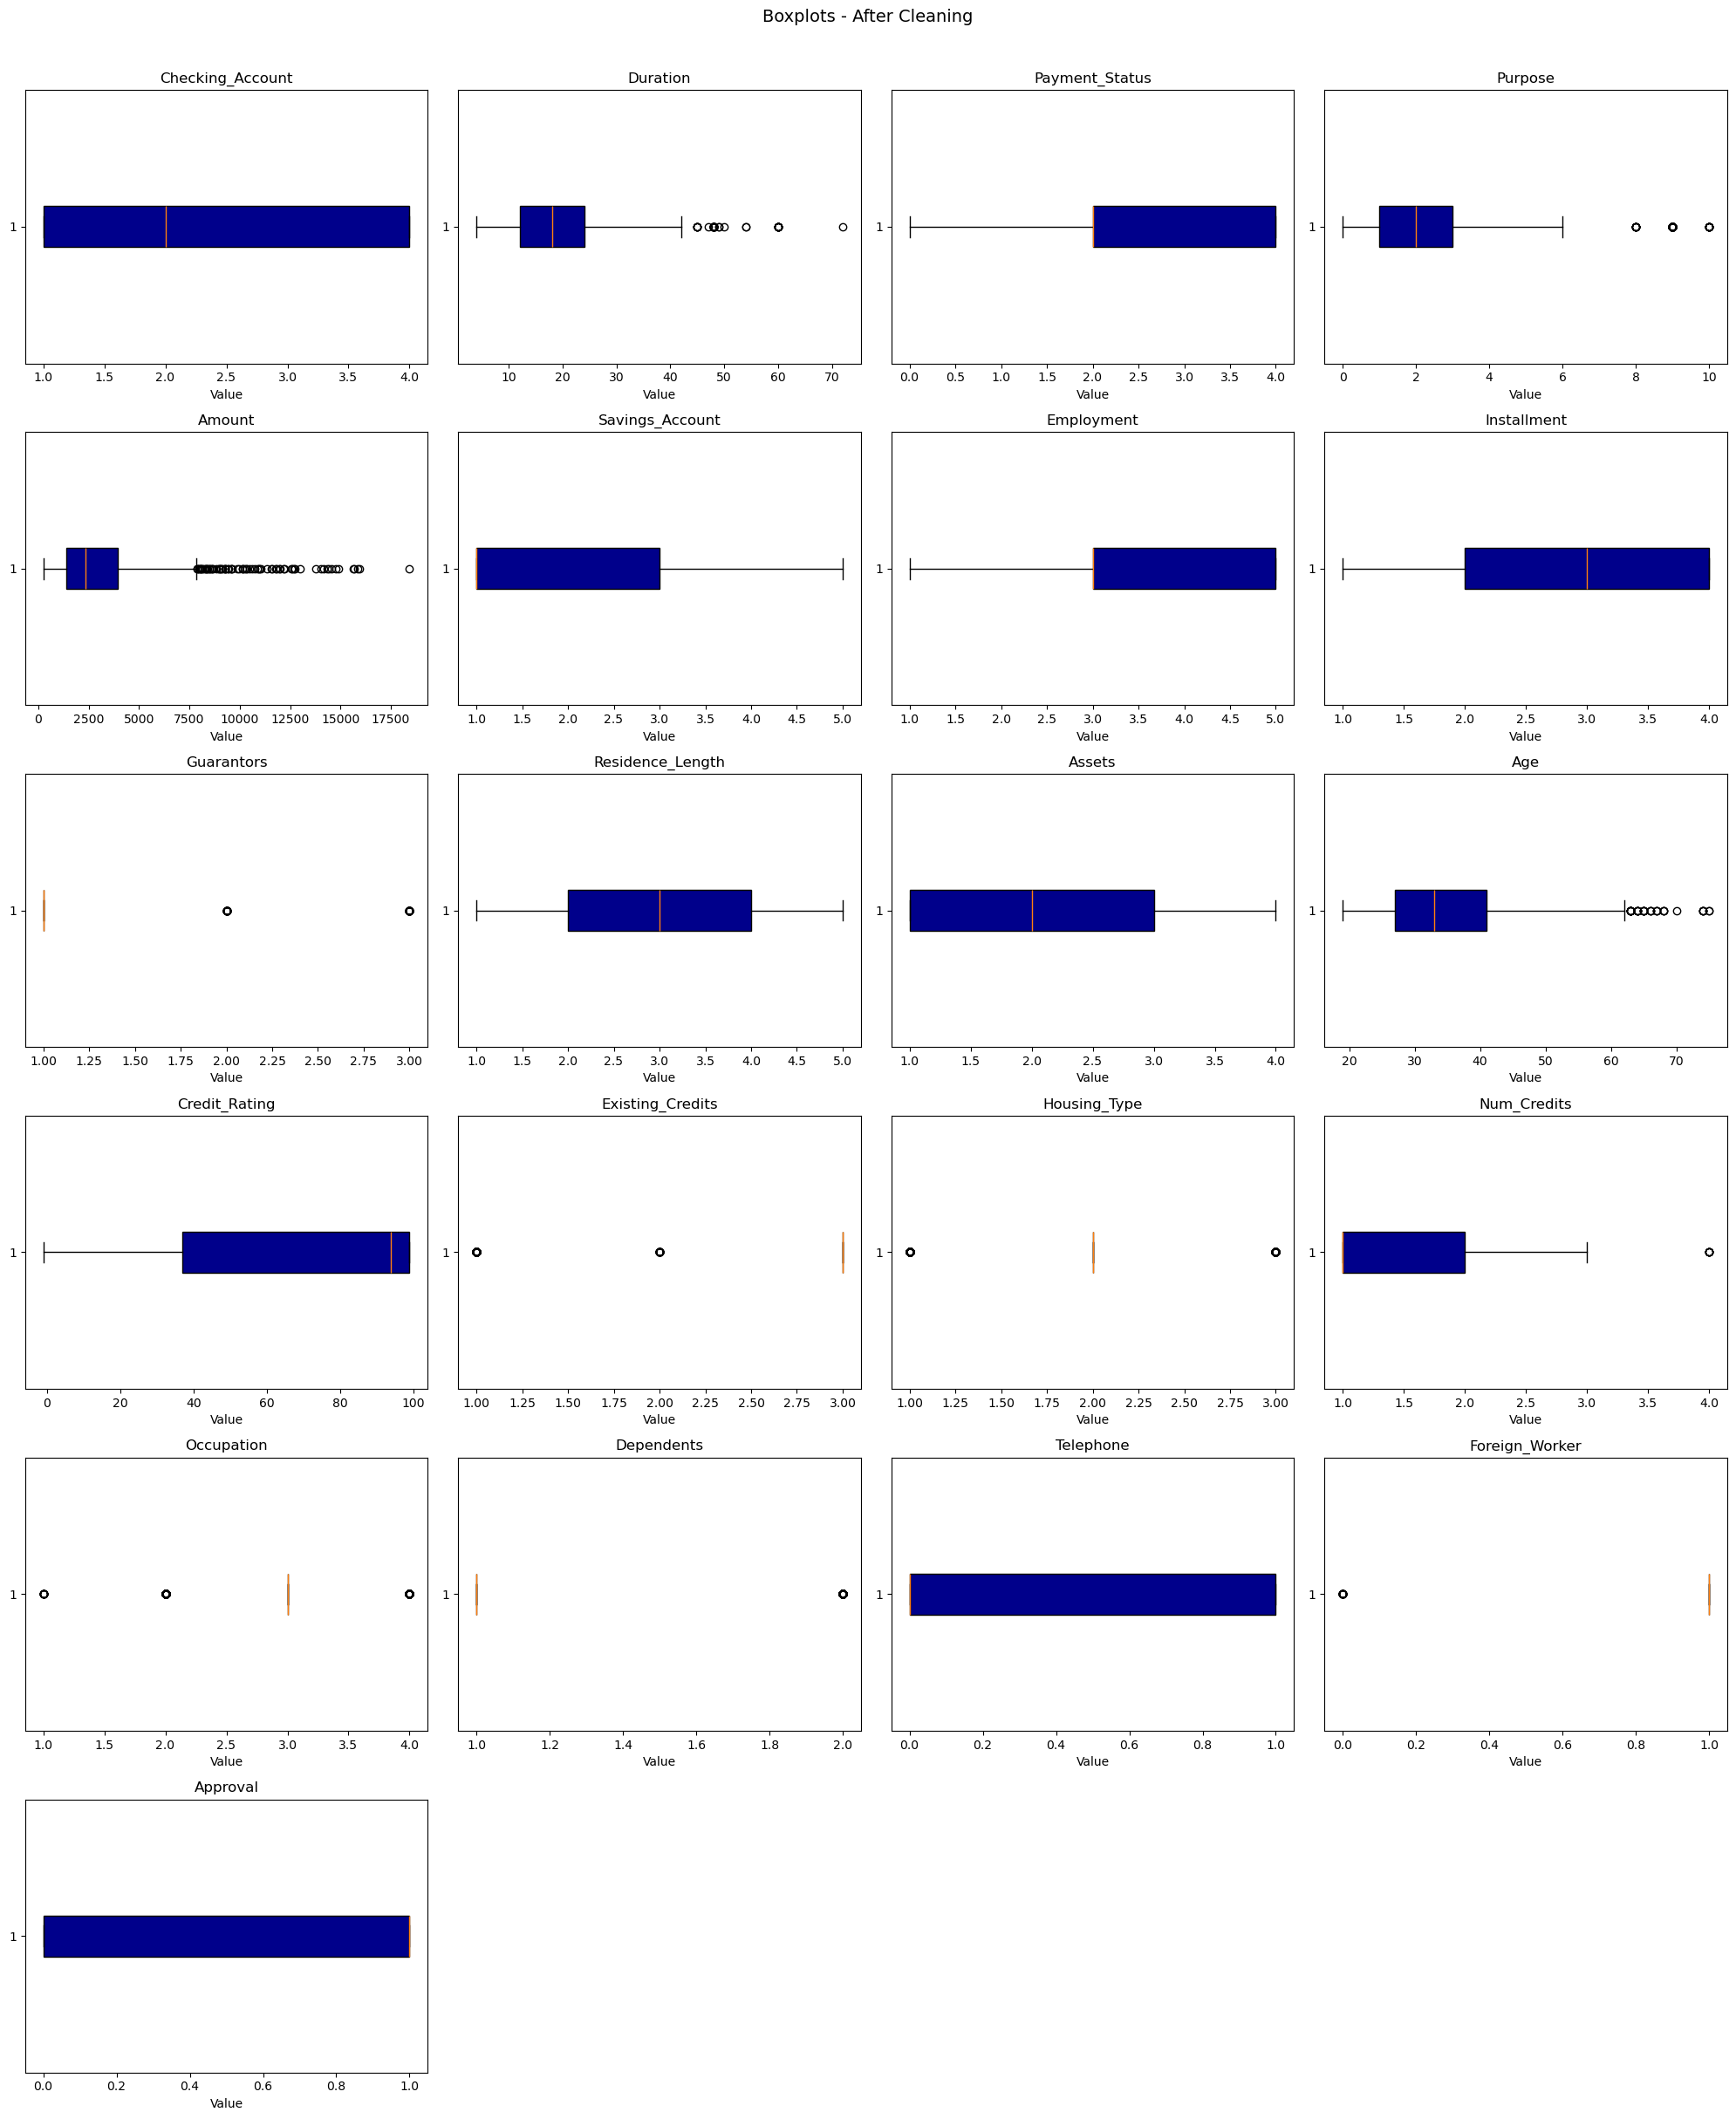

In [30]:
# Boxplots
plot_all_boxplots(df, numeric_cols_after, title_suffix='After Cleaning', filename='after_boxplots.png', color='darkblue')

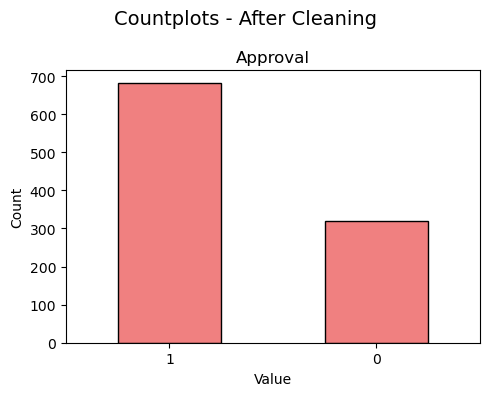

In [31]:
# Countplots
plot_all_countplots(df, categorical_cols_after, title_suffix='After Cleaning', filename='after_countplots.png')

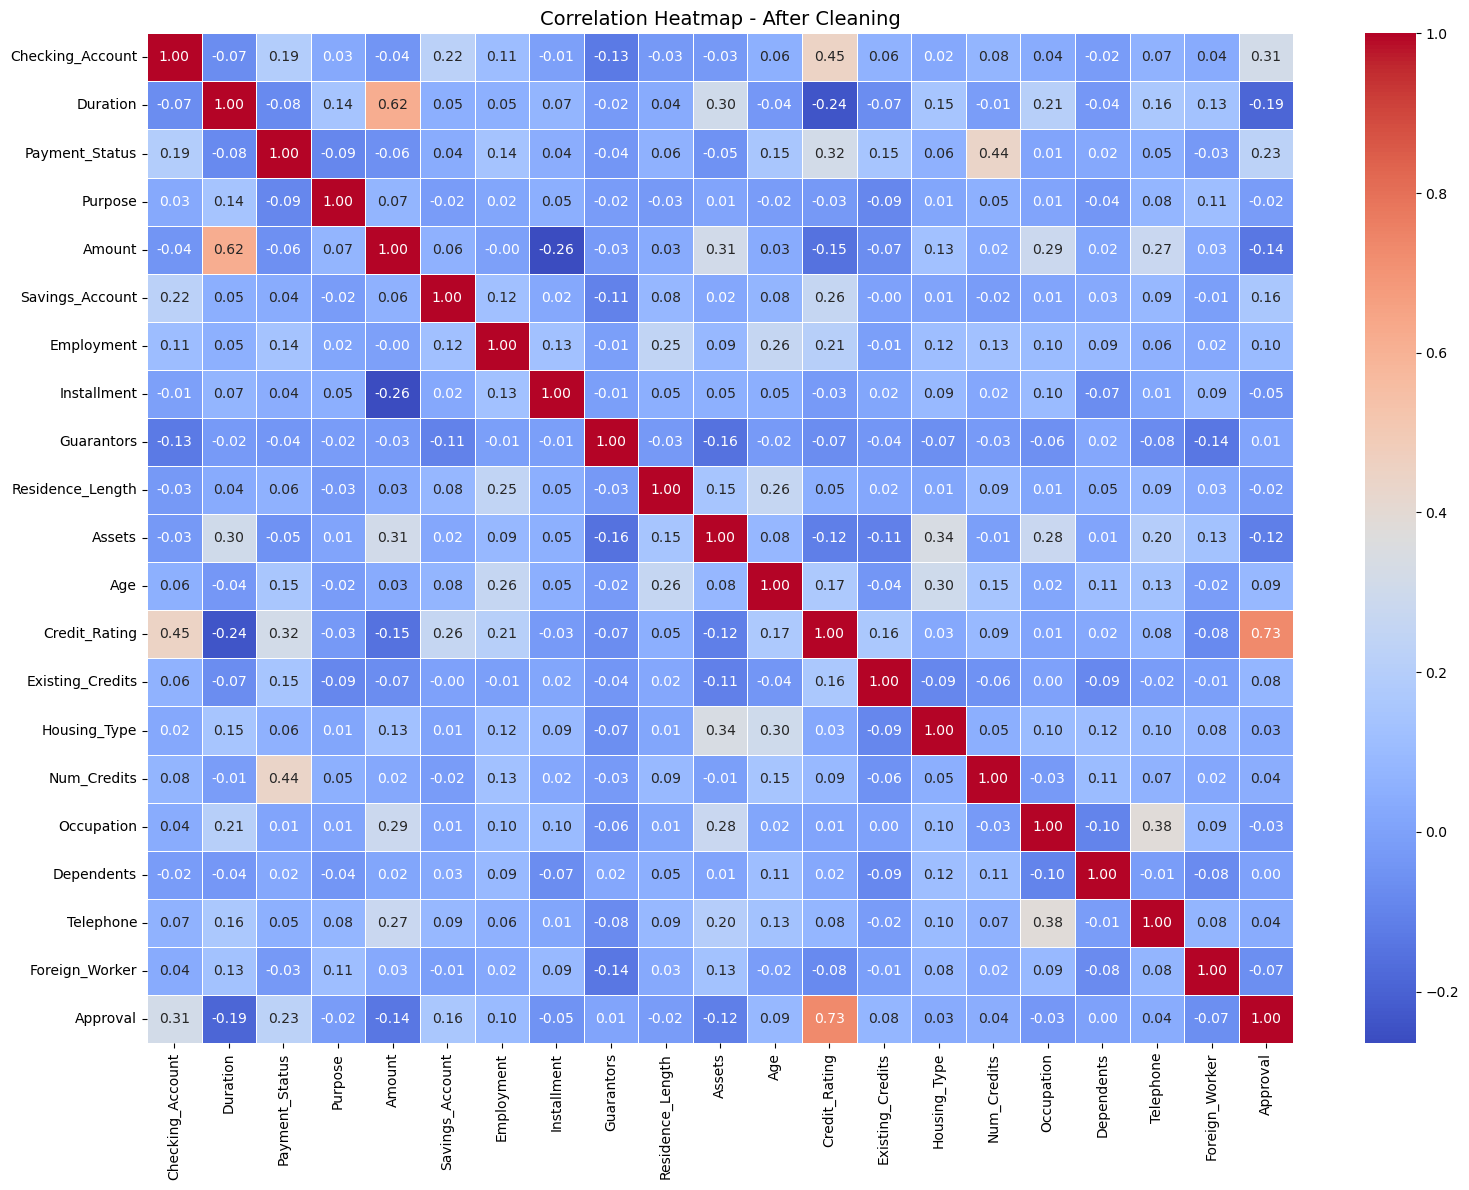

In [32]:
# Correlation heatmap (df)
plot_correlation_heatmap(df, numeric_cols_after, title_suffix='After Cleaning', filename='after_correlation_heatmap.png')

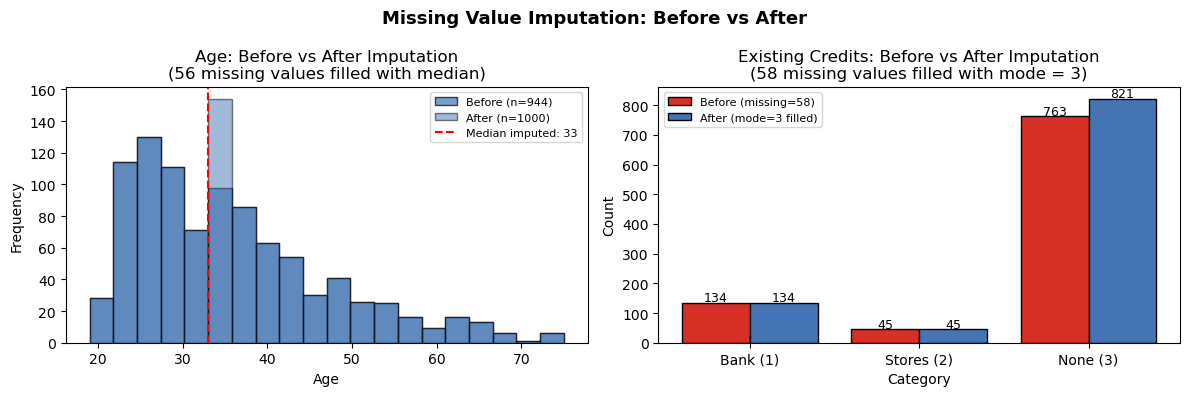

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Age — overlay missing count on histogram
axes[0].hist(df_raw['Age'].dropna(), bins=20, color='#4575b4', edgecolor='black',
             alpha=0.7, label=f'Before (n={df_raw["Age"].dropna().shape[0]})')
axes[0].hist(df['Age'], bins=20, color='#4575b4', edgecolor='black',
             alpha=0.5, label=f'After (n={df["Age"].shape[0]})')
axes[0].axvline(df_raw['Age'].median(), color='red', linestyle='--',
                linewidth=1.5, label=f'Median imputed: {df_raw["Age"].median():.0f}')
axes[0].set_title('Age: Before vs After Imputation\n(56 missing values filled with median)')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Frequency')
axes[0].legend(fontsize=8)

# Existing_Credits — grouped bar showing before vs after counts per category
import numpy as np
cats = [1, 2, 3]
before_counts = [df_raw['Existing_Credits'].value_counts().get(c, 0) for c in cats]
after_counts  = [df['Existing_Credits'].value_counts().get(c, 0) for c in cats]
x = np.arange(len(cats))
axes[1].bar(x - 0.2, before_counts, 0.4, label='Before (missing=58)',
            color='#d73027', edgecolor='black')
axes[1].bar(x + 0.2, after_counts,  0.4, label='After (mode=3 filled)',
            color='#4575b4', edgecolor='black')
axes[1].set_xticks(x)
axes[1].set_xticklabels(['Bank (1)', 'Stores (2)', 'None (3)'])
axes[1].set_title('Existing Credits: Before vs After Imputation\n(58 missing values filled with mode = 3)')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Count')
axes[1].legend(fontsize=8)
for i, (b, a) in enumerate(zip(before_counts, after_counts)):
    axes[1].text(i - 0.2, b + 5, str(b), ha='center', fontsize=9)
    axes[1].text(i + 0.2, a + 5, str(a), ha='center', fontsize=9)

plt.suptitle('Missing Value Imputation: Before vs After', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('compare_imputation.png', dpi=150, bbox_inches='tight')
plt.show()